# Public health analysis — Data wrangling

This notebook turns the thirteen raw CSVs in `../data/raw/` (downloaded by hand from Our World in Data — `data/raw/README.md` has the exact links) into one tidy country-year panel that every other notebook in this project analyses.

**What happens here:**

- inspect each raw file and note the quirks (there are a few good ones),
- filter the entity list down to real countries — OWID mixes in "World", "High-income countries" and friends,
- harmonise units: under-five mortality arrives as a *percentage*, the literature speaks deaths per 1,000 live births,
- outer-merge everything on country + year, keeping missing values as `NaN` (never zero-filled),
- save `data/processed/panel.csv` and `data/processed/world.csv`.

No analysis in this one. It's all plumbing — but the kind of plumbing worth doing carefully, because every number downstream depends on it.

In [1]:
# Setup block -- I keep a copy of this at the top of every notebook so each one
# runs on its own. Muted grid, no top/right spines, one look across all figures.
from functools import reduce
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#D8DEE4", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "xtick.labelsize": 10, "ytick.labelsize": 10,
    "axes.labelsize": 10.5, "axes.labelcolor": "#4A5560",
    "axes.titlesize": 15, "axes.titleweight": "bold",
    "axes.titlepad": 14, "axes.titlecolor": "#1A2530",
    "legend.frameon": False, "legend.fontsize": 9.5,
    "figure.dpi": 110, "savefig.dpi": 200,
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

NEUTRAL, NEUTRAL_LIGHT, GRID = "#4A5560", "#9AA7B2", "#E8EDF1"
SOURCE_NOTE = ("Source: Our World in Data (UN WPP 2024, UN IGME 2024, World Bank, "
               "WHO GHO, IHME GBD, Maddison Project). CC BY 4.0.")

def headline(ax, title, subtitle=None):
    """Finding-first title (left, bold), muted subtitle underneath."""
    ax.set_title(title, loc="left", pad=34 if subtitle else 14)
    if subtitle:
        ax.text(0, 1.045, subtitle, transform=ax.transAxes,
                fontsize=10, color=NEUTRAL, va="bottom")

def clean_axis(ax, grid=True, axis="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if grid:
        ax.grid(axis=axis, color=GRID, linewidth=0.7)
        ax.set_axisbelow(True)

def save(fig, name, note=SOURCE_NOTE):
    """Save into ../figures with the source attribution in the bottom corner."""
    if note:
        fig.text(0.006, 0.008, note, fontsize=7.5, color=NEUTRAL_LIGHT, va="bottom")
        try:
            # reserve the bottom strip so the layout engine keeps the x-label
            # from crashing into the source note
            fig.get_layout_engine().set(rect=(0, 0.042, 1, 0.958))
        except Exception:
            pass  # cosmetic only, different matplotlib versions rename this API
    path = f"../figures/{name}.png"
    fig.savefig(path, dpi=200, facecolor="white")
    plt.show()
    print("saved", path)

raw = Path("../data/raw")

In [2]:
# what we're working with
sorted(p.name for p in raw.glob("*.csv"))

['air_pollution_deaths.csv',
 'child_mortality.csv',
 'continents.csv',
 'dtp3_immunization.csv',
 'gdp_per_capita.csv',
 'health_spending.csv',
 'life_expectancy.csv',
 'obesity.csv',
 'population.csv',
 'sanitation_access.csv',
 'schooling.csv',
 'smoking.csv',
 'water_access.csv']

## 1. What an OWID export looks like

Every OWID chart download has the same three leading columns — `Entity`, `Code`, `Year` — followed by the indicator columns. The important gotcha: **rows without a `Code` are aggregates** ("World", "European Union (27)", "High-income countries", ...). Leave them in and "the average country" quietly becomes a mix of countries and continent-sized blocs.

My filter: keep an entity only if it appears in `continents.csv`, OWID's own country-to-continent mapping. That file lists countries and territories only — a cleaner definition of "country" than any string-matching I could write — and I get continent labels for free.

In [3]:
regions = pd.read_csv(raw / "continents.csv")
regions = (regions[["Entity", "Code", "World region according to OWID"]]
           .drop_duplicates("Entity")
           .rename(columns={"World region according to OWID": "region", "Code": "region_code"}))

print(f"{len(regions)} entities in the mapping")
print(regions["region"].value_counts().to_string())
regions.head()

272 entities in the mapping
region
Europe           68
Africa           61
Asia             59
North America    43
Oceania          25
South America    16


,Entity,region_code,region
0,Afghanistan,AFG,Asia
1,Aland Islands,ALA,Europe
2,Albania,ALB,Europe
3,Algeria,DZA,Africa
4,American Samoa,ASM,Oceania


## 2. The indicator registry

One place that says which file contributes which column, and what (if anything) to do to the units on the way in. The source columns are OWID's exact spellings — that's what the loader has to match against, typos included.

In [4]:
# key -> (file, source column, unit transform)
INDICATORS = {
    "life_expectancy":      ("life_expectancy.csv",      "Life expectancy", None),
    "child_mortality":      ("child_mortality.csv",      "Under-five mortality rate (selected)", "per_1000"),
    "gdp_pc":               ("gdp_per_capita.csv",       "GDP per capita", None),
    "schooling":            ("schooling.csv",            "Average years of schooling", None),
    "health_spending_pc":   ("health_spending.csv",      "Current health expenditure per capita, PPP (current international $)", None),
    "dtp3":                 ("dtp3_immunization.csv",    "DTP3 (% of one-year-olds immunized)", None),
    "smoking":              ("smoking.csv",              "Share of adults who smoke or use tobacco (age-standardized)", None),
    "obesity":              ("obesity.csv",              "Obesity among adults, BMI >= 30 kg/m2 (crude estimate) (%) - Sex: both sexes - Age group: 18+  years of age", None),
    "air_pollution_deaths": ("air_pollution_deaths.csv", "Age-standardized mortality rate attributed to ambient air pollution (deaths per 100,000 population)", None),
    "water_access":         ("water_access.csv",         "Using improved drinking water soures", None),  # sic -- OWID's typo
    "sanitation_access":    ("sanitation_access.csv",    "Access to improved sanitation facilities", None),
    "stunting":             ("sanitation_access.csv",    "Share of children who are stunted", None),
    "population":           ("population.csv",           "Population", None),
}

The loader reads one file, checks the expected column still exists (OWID renames things occasionally — this is the line that will scream if they do), applies the unit transform, and drops duplicate `(Entity, Year)` rows. A few files stitch sources together and carry both the old and the new observation for the same year; I keep the later one.

In [5]:
def load_indicator(key):
    """Read one raw file -> tidy frame: Entity, Code, Year, <key>."""
    file, column, transform = INDICATORS[key]
    df = pd.read_csv(raw / file)
    if column not in df.columns:
        raise KeyError(f"{file}: expected column '{column}' not found -- OWID may have renamed it")

    out = df[["Entity", "Code", "Year", column]].rename(columns={column: key})
    if transform == "per_1000":
        out[key] = out[key] * 10.0   # percent -> deaths per 1,000 live births

    out = (out.dropna(subset=[key])
              .drop_duplicates(subset=["Entity", "Year"], keep="last"))
    return out

le = load_indicator("life_expectancy")
le.head()

,Entity,Code,Year,life_expectancy
0,Afghanistan,AFG,1950,28.1563
1,Afghanistan,AFG,1951,28.5836
2,Afghanistan,AFG,1952,29.0138
3,Afghanistan,AFG,1953,29.4521
4,Afghanistan,AFG,1954,29.6975


## 3. Quirks I hit (so you don't have to)

- **Child mortality is a percentage.** OWID's column is the probability of dying before age five, in percent. Global-health practice is deaths per 1,000 live births, hence the ×10. There's a sanity check below against the UN IGME's published world figure — this is exactly the kind of unit bug you want to catch in data_wrangling.ipynb, not in child_survival.ipynb.
- **The water file's typo.** The column header really is `Using improved drinking water soures`. Preserved verbatim in the registry; if OWID ever fixes it, that registry is the single place to update.
- **Maddison GDP starts at year 1.** A handful of economies have estimates back to antiquity. Fascinating, but not comparable to anything here — the panel starts at 1950.
- **Population goes back to −10000** via the HYDE database. Same treatment.
- **Air pollution is a single cross-section** (IHME GBD 2019 estimates, one row per country). Fine for maps and correlations, useless for trends.
- **Sanitation and stunting ship in the same file** because OWID publishes them as one scatter chart; the registry just pulls two columns out of it.

In [6]:
# the sanity check: UN IGME puts world under-five mortality in 1990 at ~93
# deaths per 1,000 live births
cm = load_indicator("child_mortality")
w1990 = cm[(cm["Entity"] == "World") & (cm["Year"] == 1990)]
print(f"world U5MR 1990 after transform: {w1990['child_mortality'].iloc[0]:.1f} per 1,000 live births")

for f in ["gdp_per_capita.csv", "population.csv", "air_pollution_deaths.csv"]:
    d = pd.read_csv(raw / f)
    print(f"{f:26s} years {d['Year'].min():>7} to {d['Year'].max()}")

world U5MR 1990 after transform: 93.5 per 1,000 live births
gdp_per_capita.csv         years       1 to 2022
population.csv             years  -10000 to 2023
air_pollution_deaths.csv   years    2019 to 2019


## 4. Build the panel

For each indicator: keep country rows only (via the mapping above), clip to 1950–2024, note the coverage. Then one big **outer** join on `(Entity, Code, Year)` — outer, deliberately: indicators start and end in different years, and the panel should preserve each one's own coverage instead of silently truncating to the intersection. Missing stays `NaN`; nothing is ever zero-filled.

The `World` rows are pulled out into a separate frame. Where OWID's sources publish a world aggregate I'd much rather use theirs than compute my own — the UN's world life expectancy is a properly constructed aggregate, not the average of country values.

In [7]:
country_names = set(regions["Entity"])

frames, world_frames, coverage_rows = [], [], []
for key in INDICATORS:
    df = load_indicator(key)

    countries = df[df["Entity"].isin(country_names)]
    countries = countries[countries["Year"].between(1950, 2024)]

    wld = (df[df["Entity"] == "World"]
           .drop(columns=["Code"])
           .rename(columns={"Entity": "country"}))
    wld = wld[wld["Year"] <= 2024]

    frames.append(countries)
    if len(wld):
        world_frames.append(wld)

    coverage_rows.append({
        "indicator": key,
        "countries": countries["Entity"].nunique(),
        "year_min": int(countries["Year"].min()),
        "year_max": int(countries["Year"].max()),
        "observations": len(countries),
    })

coverage = pd.DataFrame(coverage_rows).sort_values("indicator").reset_index(drop=True)
coverage

,indicator,countries,year_min,year_max,observations
0,air_pollution_deaths,183,2019,2019,183
1,child_mortality,201,1950,2024,13326
2,dtp3,194,1980,2024,8100
3,gdp_pc,169,1950,2022,11822
4,health_spending_pc,193,2000,2024,4561
5,life_expectancy,237,1950,2023,17538
6,obesity,199,1980,2024,8955
7,population,247,1950,2023,17877
8,sanitation_access,232,2000,2024,5597
9,schooling,146,1950,2020,1735


In [8]:
panel = reduce(lambda l, r: pd.merge(l, r, on=["Entity", "Code", "Year"], how="outer"), frames)
panel = panel.merge(regions[["Entity", "region"]], on="Entity", how="left")
panel = panel.rename(columns={"Entity": "country", "Code": "iso3", "Year": "year"})

# identifiers and context first, then outcomes, then system / risk / socioeconomic
ORDER = ["country", "iso3", "region", "year",
         "life_expectancy", "child_mortality", "stunting",
         "dtp3", "smoking", "obesity", "air_pollution_deaths",
         "gdp_pc", "health_spending_pc", "schooling",
         "water_access", "sanitation_access", "population"]
panel = panel[ORDER].sort_values(["country", "year"]).reset_index(drop=True)

# the checks I want any panel to pass before I trust it
assert not panel.duplicated(["country", "year"]).any()
assert panel["year"].between(1950, 2024).all()
assert panel["region"].notna().all()
print(f"{len(panel):,} rows · {panel['country'].nunique()} countries · "
      f"{panel['year'].min()}-{panel['year'].max()}")

18,273 rows · 248 countries · 1950-2024


In [9]:
# a few territories use OWID-prefixed codes instead of ISO-3166 -- Kosovo is
# the one that matters here (it keeps a full data series, so it stays)
panel.loc[panel["iso3"].str.startswith("OWID", na=False), ["country", "iso3"]].drop_duplicates()

,country,iso3
4050,Czechoslovakia,OWID_CZS
4498,East Germany,OWID_GDR
5176,Ethiopia (former),OWID_ERE
8445,Kosovo,OWID_KOS
14356,Serbia and Montenegro,OWID_SRM
15462,Sudan (former),OWID_SDN
16809,USSR,OWID_USS
17856,West Germany,OWID_GFR
18008,Yemen Arab Republic,OWID_YAR
18029,Yemen People's Republic,OWID_YPR


In [10]:
world = (reduce(lambda l, r: pd.merge(l, r, on=["country", "Year"], how="outer"), world_frames)
         .rename(columns={"Year": "year"})
         .sort_values("year")
         .reset_index(drop=True))
world.tail(3)

,country,year,life_expectancy,child_mortality,gdp_pc,schooling,health_spending_pc,dtp3,smoking,obesity,air_pollution_deaths,water_access,sanitation_access,population
259,World,2022,72.6398,40.0,16676.75,NaN,1803.3635,85.0,21.132626,15.583217,NaN,94.363090,87.455795,8.021407e+09
260,World,2023,73.1694,38.3,NaN,NaN,1891.1688,84.0,20.712840,15.992740,NaN,94.709114,88.205230,8.091735e+09
261,World,2024,NaN,37.4,NaN,NaN,NaN,84.0,20.280697,16.414158,NaN,94.989660,88.864690,NaN


## 5. Coverage — the first honest look at the data

This is the table I come back to whenever a downstream number looks odd. Two things worth internalising early. First, completeness is very uneven: air pollution is a single year, life expectancy is seventy-four of them. Second, the countries missing from the sparse indicators are disproportionately poor and conflict-affected — **missingness is not random**, which matters for every correlation in socioeconomic_links.ipynb (see `docs/limitations.md`).

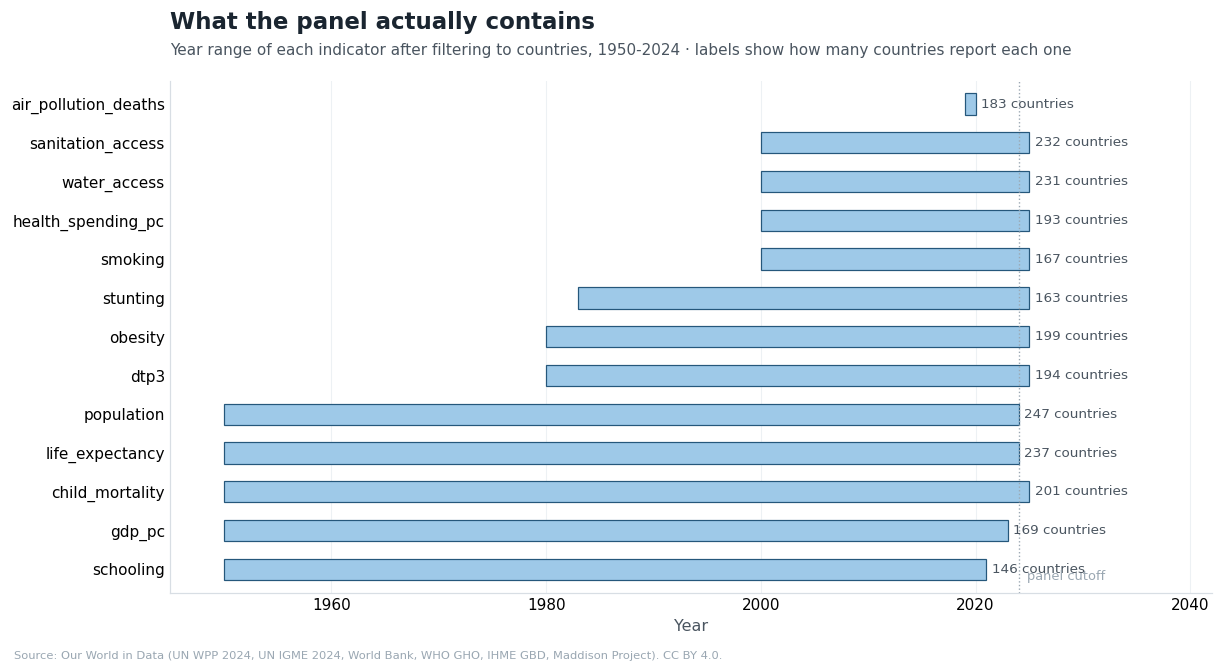

saved ../figures/data_coverage.png


In [11]:
fig, ax = plt.subplots(figsize=(11, 6), constrained_layout=True)

cov = coverage.sort_values(["year_min", "countries"]).reset_index(drop=True)
ypos = np.arange(len(cov))
ax.barh(ypos, cov["year_max"] - cov["year_min"] + 1, left=cov["year_min"],
        height=0.55, color="#9EC9E8", edgecolor="#25577B", linewidth=0.8)
for y, row in zip(ypos, cov.itertuples()):
    ax.text(row.year_max + 1.5, y, f"{row.countries} countries",
            va="center", fontsize=8.8, color=NEUTRAL)

ax.set_yticks(ypos)
ax.set_yticklabels(cov["indicator"])
ax.set_xlim(1945, 2042)
ax.set_ylim(-0.6, len(cov) - 0.4)
ax.axvline(2024, color=NEUTRAL_LIGHT, lw=0.9, ls=":")
ax.text(2024.8, -0.35, "panel cutoff", fontsize=8.5, color=NEUTRAL_LIGHT, va="bottom")
ax.set_xlabel("Year")
clean_axis(ax, grid=False, axis="x")
ax.xaxis.grid(True, color="#EDF1F4", linewidth=0.7)
ax.set_axisbelow(True)
headline(ax, "What the panel actually contains",
         "Year range of each indicator after filtering to countries, 1950-2024 · "
         "labels show how many countries report each one")
save(fig, "data_coverage")

In [12]:
panel.to_csv("../data/processed/panel.csv", index=False)
world.to_csv("../data/processed/world.csv", index=False)
coverage.to_csv("../data/processed/data_coverage.csv", index=False)
print("saved panel.csv, world.csv, data_coverage.csv -> ../data/processed/")
panel.head()

saved panel.csv, world.csv, data_coverage.csv -> ../data/processed/


,country,iso3,region,year,life_expectancy,child_mortality,stunting,dtp3,smoking,obesity,air_pollution_deaths,gdp_pc,health_spending_pc,schooling,water_access,sanitation_access,population
0,Afghanistan,AFG,Asia,1950,28.1563,NaN,NaN,NaN,NaN,NaN,NaN,1156.0,NaN,0.28,NaN,NaN,7776180.0
1,Afghanistan,AFG,Asia,1951,28.5836,NaN,NaN,NaN,NaN,NaN,NaN,1170.0,NaN,NaN,NaN,NaN,7879343.0
2,Afghanistan,AFG,Asia,1952,29.0138,NaN,NaN,NaN,NaN,NaN,NaN,1189.0,NaN,NaN,NaN,NaN,7987784.0
3,Afghanistan,AFG,Asia,1953,29.4521,NaN,NaN,NaN,NaN,NaN,NaN,1240.0,NaN,NaN,NaN,NaN,8096703.0
4,Afghanistan,AFG,Asia,1954,29.6975,NaN,NaN,NaN,NaN,NaN,NaN,1245.0,NaN,NaN,NaN,NaN,8207954.0


## Done — what the panel looks like

One row per country-year. 248 countries and territories, 1950–2024, thirteen indicator columns (each with its own coverage), plus `region` for grouping and `population` for weighting. The column-by-column description, units and all the quirks live in `docs/data_dictionary.md`.

Next up: **[global_trends.ipynb](global_trends.ipynb)** — the world series since 1950, regional trajectories, and whether countries are actually converging.